# **Trabajo Práctico 3 - Minería de datos - TUIA - FCEIA - UNR - 2026**

**Integrantes:**
- Fabián Alvarez - Legajo: A-4501/2
- Gonzalo Longo - L-3352/9

## **Introducción**


En este trabajo práctico se analiza un problema de clasificación multiclase utilizando técnicas de minería de datos y aprendizaje automático. El objetivo es determinar el cultivo más adecuado a partir de variables relacionadas con las características del suelo y las condiciones climáticas.

Para ello, se realiza un análisis exploratorio de los datos, el preprocesamiento del dataset y el entrenamiento de distintos modelos de clasificación. Finalmente, se comparan sus resultados mediante diferentes métricas de evaluación para identificar el modelo con mejor desempeño.

---

## **Descripción del dataset**


- **Dataset:** Recomendación de cultivo ([Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset))
- **Archivo:** `dxCropRecommendation.csv` (versión adaptada por la cátedra)
- **Variables predictoras:** Nitrógeno, Fósforo, Potasio, Temperatura, Humedad, pH, Lluvia
- **Variable objetivo:** Cultivo (clasificación multiclase)



| <font size="4"><b>Variable</b></font> | <font size="4"><b>Descripción</b></font> |
|-----------|-------------|
| <font size="3"><b>Nitrogeno</b></font> | <font size="3">Contenido de nitrógeno en suelo.</font> |
| <font size="3"><b>Fosforo</b></font> | <font size="3">Contenido de fósforo en suelo.</font> |
| <font size="3"><b>Potasio</b></font> | <font size="3">Contenido de potasio en suelo.</font> |
| <font size="3"><b>Temperatura</b></font> | <font size="3">Temperatura en °C.</font> |
| <font size="3"><b>Humedad</b></font> | <font size="3">Humedad relativa en %.</font> |
| <font size="3"><b>pH</b></font> | <font size="3">pH del suelo.</font> |
| <font size="3"><b>Lluvia</b></font> | <font size="3">Precipitaciones en mm.</font> |
| <font size="3"><b>Cultivo</b></font> | <font size="3">Cultivo recomendado (variable objetivo).</font> |

---

## **Librerías necesarias**

In [ ]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
import warnings
warnings.filterwarnings('ignore')

# Preprocesamiento y división de datos
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Modelos de clasificación
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


---

## **1. Análisis Exploratorio de Datos (EDA)**

### **1.1 Carga de datos**

In [ ]:
url = "https://drive.google.com/uc?id=1p_YJlhLd0avfQjAucffYR_pmZb_i6RwD"

df = pd.read_csv(url)
df.head()

,Nitrogeno,Fosforo,Potasio,Temperatura,Humedad,pH,Lluvia,Cultivo
0,90,42,43,20.879744,82.002744,6.502985,202.935536,Arroz
1,85,58,41,21.770462,80.319644,7.038096,226.655537,Arroz
2,60,55,44,23.004459,82.320763,7.840207,263.964248,Arroz
3,74,35,40,26.491096,80.158363,6.980401,242.864034,Arroz
4,78,42,42,20.130175,81.604873,7.628473,262.717340,Arroz


---

### **1.2 Estructura del dataset**

In [ ]:
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print()
df.info()

Filas: 1210 | Columnas: 8

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Nitrogeno    1210 non-null   int64  
 1   Fosforo      1210 non-null   int64  
 2   Potasio      1210 non-null   int64  
 3   Temperatura  1210 non-null   float64
 4   Humedad      1209 non-null   float64
 5   pH           1206 non-null   float64
 6   Lluvia       1207 non-null   float64
 7   Cultivo      1210 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 75.8+ KB


---

### **1.3 Estadísticas descriptivas**

In [ ]:
df.describe().round(2)

,Nitrogeno,Fosforo,Potasio,Temperatura,Humedad,pH,Lluvia
count,1210.00,1210.00,1210.00,1210.00,1209.00,1206.00,1207.00
mean,46.67,61.56,61.35,24.59,69.83,6.50,105.92
std,34.12,38.68,64.26,5.27,21.15,0.73,49.72
min,0.00,5.00,5.00,8.83,14.26,4.51,35.03
25%,20.00,29.00,21.00,21.12,60.48,5.96,71.76
50%,36.00,58.00,35.00,24.51,73.63,6.42,99.34
75%,78.00,78.00,55.00,27.74,84.97,7.01,113.33
max,120.00,145.00,205.00,41.95,95.00,8.87,298.56


**Interpretación**

- Se observan **valores faltantes leves** en `Humedad`, `pH` y `Lluvia` (conteo menor a 1210), que se tratarán en el preprocesamiento.

- Las variables de nutrientes (`Nitrógeno, Fósforo y Potasio`) presentan **alta variabilidad**, especialmente Potasio, con un valor máximo bastante alejado del percentil 75, lo que sugiere posibles outliers.

- En las variables climáticas, `Lluvia` también muestra cierta dispersión, con valores máximos elevados respecto a la mayoría de los datos.

---

### **1.4 Distribuciones**

- #### **Variables predictoras**

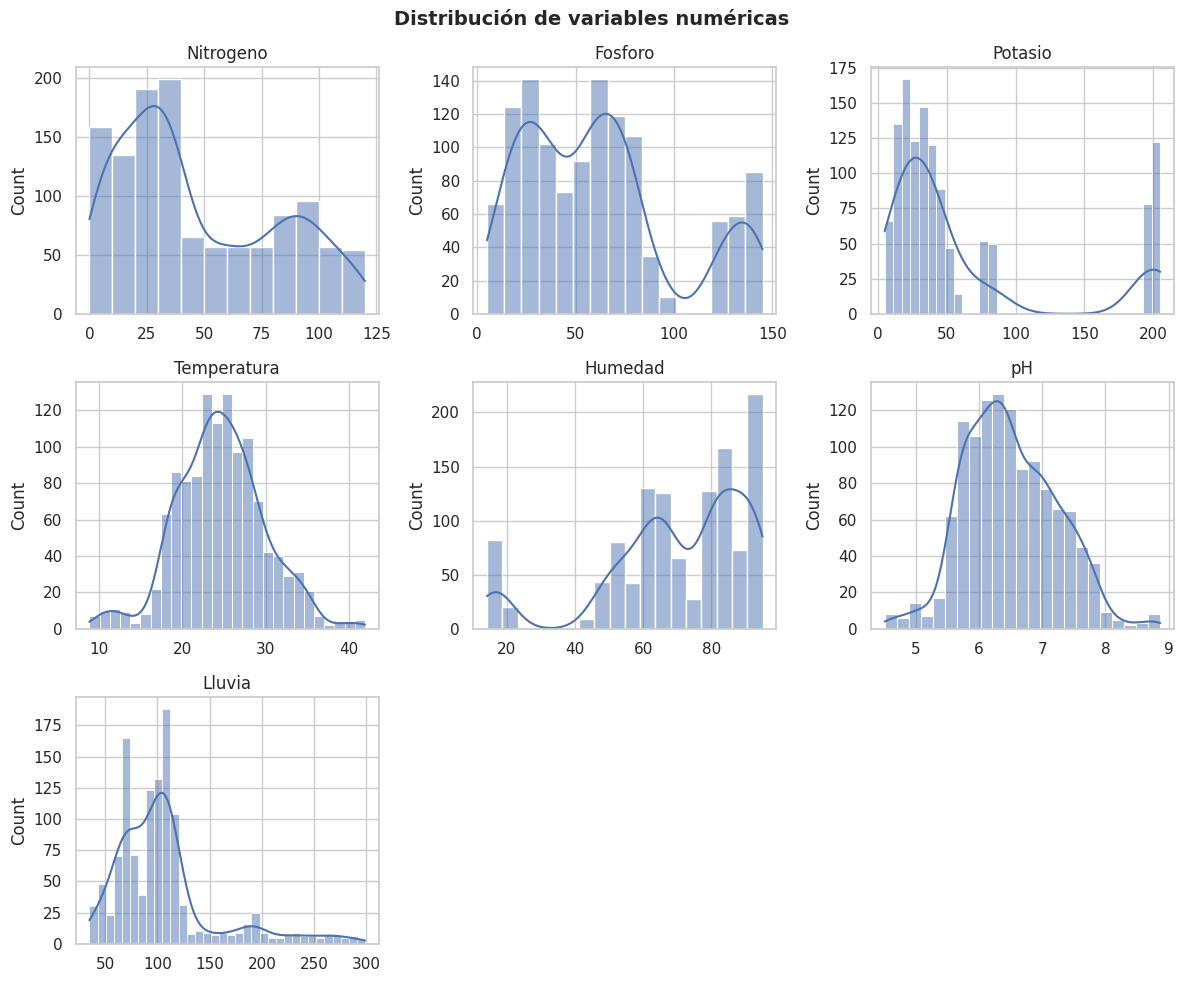

In [ ]:
num_cols = df.columns.drop('Cultivo')

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# ocultar los ejes sobrantes
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')

plt.suptitle('Distribución de variables numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretación:**

- `Nitrógeno, Fósforo y Potasio` presentan distribuciones bimodales, es decir, con dos grupos bien diferenciados de valores. Esto indica que los cultivos del dataset se dividen en al menos dos perfiles distintos respecto a los nutrientes del suelo.

- `Potasio`, en particular, tiene un pico marcado cerca de 200, bastante separado del resto, lo que sugiere la presencia de outliers o un subgrupo de cultivos con valores muy altos.

- `Temperatura` sigue una distribución aproximadamente normal, concentrada entre 20 y 30°C.

- `Humedad` tiene un comportamiento irregular, con la mayoría de los valores entre 60 y 90%, pero también un grupo pequeño cerca de 15-20%, bastante alejado del resto.

- `pH` presenta una distribución asimétrica hacia la derecha, con la mayoría de los valores concentrados entre 5.5 y 7, y una cola que se extiende hasta cerca de 9.

- `Lluvia` está concentrada entre 50 y 150 mm, pero con una cola que llega a 300 mm, lo que podría indicar outliers.

---

- #### **Variable objetivo**

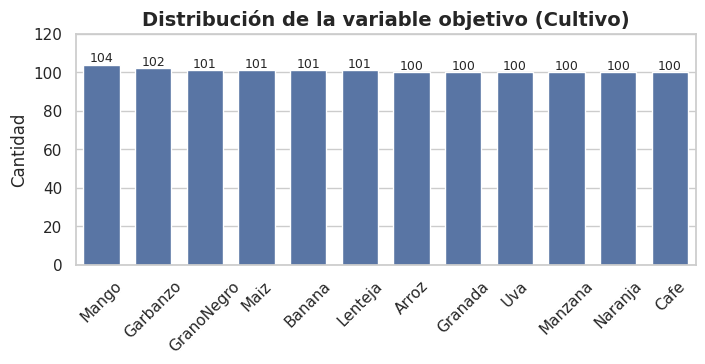

In [ ]:
plt.figure(figsize=(8, 3))
ax = sns.countplot(
    data=df,
    x='Cultivo',
    order=df['Cultivo'].value_counts().index,
    width=0.7
)

plt.title('Distribución de la variable objetivo (Cultivo)', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)

# límite en eje Y
plt.ylim(0, 120)

# valores arriba de cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.show()

**Interpretación:**

- Las 12 clases de la variable objetivo están muy bien balanceadas, con entre 100 y 104 muestras cada una. Esto es favorable para el entrenamiento de los modelos, ya que ninguna clase domina sobre las demás y no se esperan sesgos por desbalance de clases.

---

### **1.5 Correlaciones**

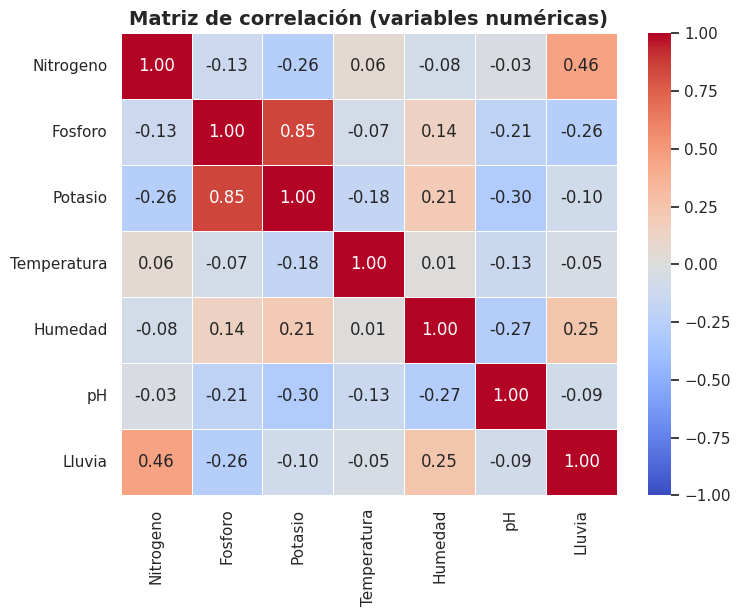

In [ ]:
num_cols = df.columns.drop('Cultivo')

corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de correlación (variables numéricas)', fontsize=14, fontweight='bold')
plt.show()

**Interpretación:**

- La mayoría de las variables tienen correlaciones bajas entre sí, lo que es positivo porque significa que cada una aporta información propia al modelo.

- El par más destacado es `Fósforo` y `Potasio`, con una correlación alta de 0.85, lo que indica que tienden a crecer juntos.

- También hay una correlación moderada entre `Nitrógeno` y `Lluvia` (0.46).

- El resto de las correlaciones son débiles, tanto positivas como negativas.

---

### **1.6 Valores faltantes**

In [ ]:
# Valores faltantes por columna
faltantes = df.isnull().sum()
faltantes_pct = (faltantes / len(df) * 100).round(2)

resumen_faltantes = pd.DataFrame({
    'Faltantes': faltantes,
    'Porcentaje (%)': faltantes_pct
})

resumen_faltantes

,Faltantes,Porcentaje (%)
Nitrogeno,0,0.00
Fosforo,0,0.00
Potasio,0,0.00
Temperatura,0,0.00
Humedad,1,0.08
pH,4,0.33
Lluvia,3,0.25
Cultivo,0,0.00


**Interpretación:**

- Se encontraron valores faltantes en tres columnas:
  - `Humedad` (1 valor, 0.08%)
  - `pH` (4 valores, 0.33%)
  - `Lluvia` (3 valores, 0.25%).

- El resto de las variables no presenta faltantes.

**Decisión:**  
  
Como la cantidad de faltantes es muy pequeña en todos los casos, se decide imputar con la **mediana** de cada columna en lugar de eliminar los registros. Se prefiere la mediana por sobre la media porque es menos sensible a valores extremos, algo importante dado que anteriormente vimos que algunas variables tienen colas o asimetrías.

In [ ]:
cols_con_faltantes = ['Humedad', 'pH', 'Lluvia']

df[cols_con_faltantes] = df[cols_con_faltantes].fillna(df[cols_con_faltantes].median())

print("Cantidad de valores faltantes tras imputar: ", df.isnull().sum().sum())

Cantidad de valores faltantes tras imputar:  0


---

### **1.7 Registros duplicados**

In [ ]:
duplicados = df.duplicated().sum()
print(f"Registros duplicados: {duplicados}")

Registros duplicados: 10


**Interpretación:**

- Se encontraron **10** registros duplicados en el dataset, lo que representa menos del 1% del total de observaciones (1210).

**Decisión:**

Se **eliminan** los registros duplicados, ya que mantenerlos podría sesgar el entrenamiento de los modelos al repetir información. Al ser tan pocos, su eliminación no afecta significativamente el tamaño del dataset.

In [ ]:
df = df.drop_duplicates()
print(f"Registros tras eliminar duplicados: {len(df)}")

Registros tras eliminar duplicados: 1200


---

### **1.8 Valores atípicos**

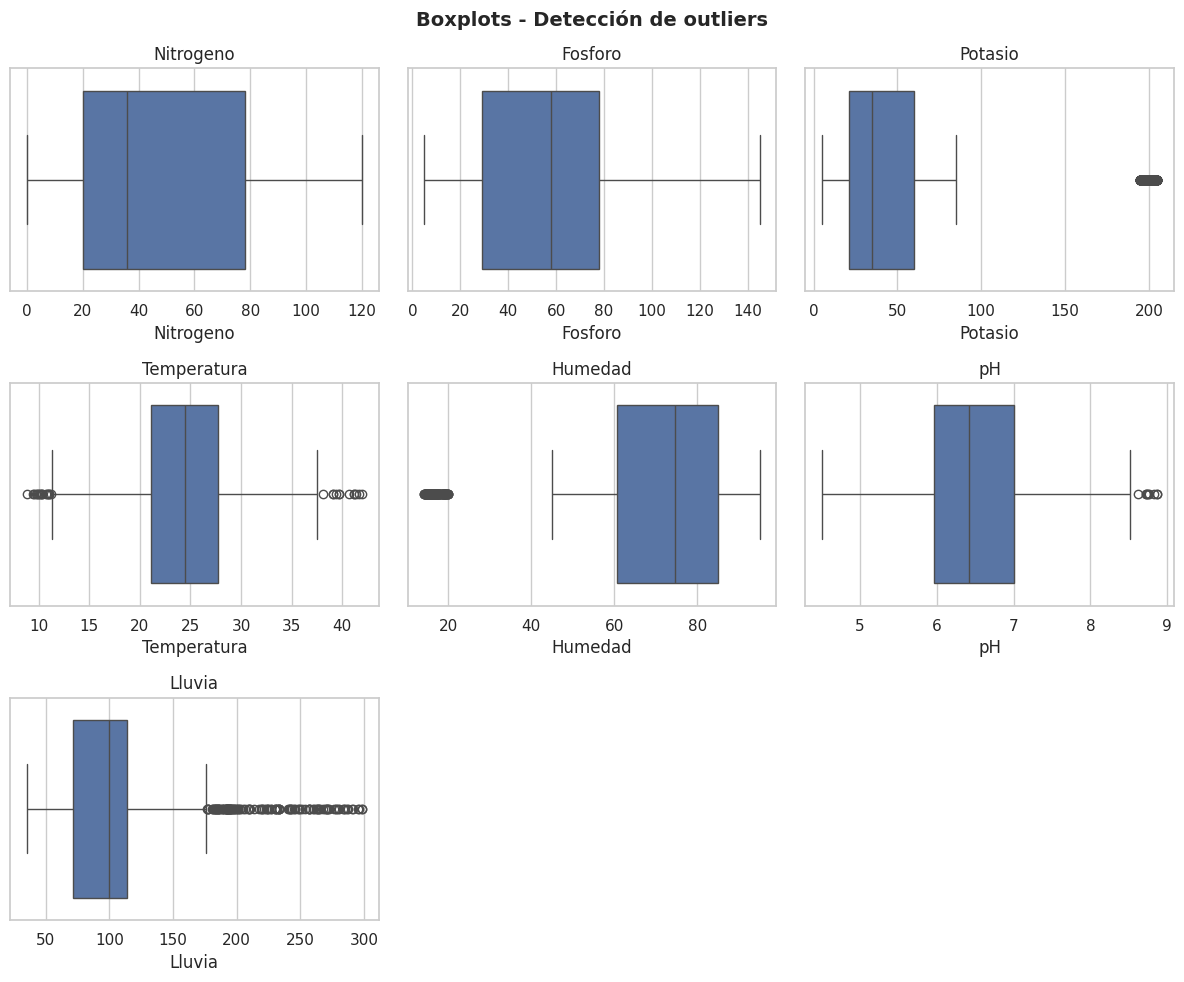

In [ ]:
num_cols = df.columns.drop('Cultivo')

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')

plt.suptitle('Boxplots - Detección de outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretación:**

- `Nitrógeno` y `Fósforo`: no muestran outliers, los bigotes cubren bien el rango de datos.  
- `Potasio`: tiene un grupo de puntos claramente separado cerca de 200, confirma lo que vimos en el histograma.  
- `Temperatura`: outliers en ambos extremos, valores bajos cerca de 8–10°C y varios valores altos cerca de 40–42°C.  
- `Humedad`: un punto muy aislado cerca de 20%, bastante separado del resto que se concentra entre 40 y 90%.  
- `pH`: algunos puntos outliers en el extremo derecho, cerca de 9.  
- `Lluvia`: es la más llamativa, con una gran cantidad de puntos dispersos entre 175 y 300 mm, bien separados de la caja principal.

**Decisión:**  

Se decide conservar los valores atípicos. Como el dataset tiene 12 cultivos muy distintos entre sí, estos valores probablemente sean las condiciones normales de algún cultivo puntual y no errores de medición. Además, en los histogramas varios de estos valores formaban grupos propios, lo que refuerza que son datos reales y válidos. Por último, al estandarizar las variables en el siguiente paso, el impacto de estos valores extremos se reduce considerablemente.

---

### **1.9 Estandarización de variables numéricas**

In [ ]:
num_cols = df.columns.drop('Cultivo')

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

---

### **1.10 Codificación de variable objetivo**

In [ ]:
le = LabelEncoder()
df['Cultivo'] = le.fit_transform(df['Cultivo'])

print("Clases codificadas:")
for i, clase in enumerate(le.classes_):
    print(f"  {i}: {clase}")

Clases codificadas:
  0: Arroz
  1: Banana
  2: Cafe
  3: Garbanzo
  4: Granada
  5: GranoNegro
  6: Lenteja
  7: Maiz
  8: Mango
  9: Manzana
  10: Naranja
  11: Uva


In [ ]:
df.head()

,Nitrogeno,Fosforo,Potasio,Temperatura,Humedad,pH,Lluvia,Cultivo
0,1.269214,-0.506561,-0.287597,-0.700929,0.570008,0.000694,1.945951,0
1,1.122636,-0.093779,-0.318638,-0.530993,0.490092,0.737252,2.422391,0
2,0.389749,-0.171175,-0.272076,-0.295565,0.585108,1.841324,3.171774,0
3,0.800166,-0.687153,-0.334159,0.369635,0.482434,0.657837,2.747955,0
4,0.917428,-0.506561,-0.303118,-0.843936,0.551116,1.549881,3.146729,0


---

## **2. SVM lineal**

### **2.1 Selección de hiperparámetros**

In [ ]:
X = df.drop('Cultivo', axis=1)
y = df['Cultivo']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13)

C_values = [0.01, 0.1, 1, 10, 100]
resultados_svm_lineal = []

for C in C_values:
    modelo = SVC(kernel='linear', C=C, random_state=13)

    acc    = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
    prec   = cross_val_score(modelo, X, y, cv=cv, scoring='precision_weighted')
    recall = cross_val_score(modelo, X, y, cv=cv, scoring='recall_weighted')

    resultados_svm_lineal.append({
        'C': C,
        'Accuracy':  f"{acc.mean():.4f} ± {acc.std():.4f}",
        'Precision': f"{prec.mean():.4f} ± {prec.std():.4f}",
        'Recall':    f"{recall.mean():.4f} ± {recall.std():.4f}"
    })

df_svm_lineal = pd.DataFrame(resultados_svm_lineal)
display(df_svm_lineal)

,C,Accuracy,Precision,Recall
0,0.01,0.9075 ± 0.0293,0.9198 ± 0.0209,0.9075 ± 0.0293
1,0.10,0.9933 ± 0.0068,0.9937 ± 0.0063,0.9933 ± 0.0068
2,1.00,0.9975 ± 0.0033,0.9975 ± 0.0033,0.9975 ± 0.0033
3,10.00,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
4,100.00,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017


### **2.2 Comparación de configuraciones**

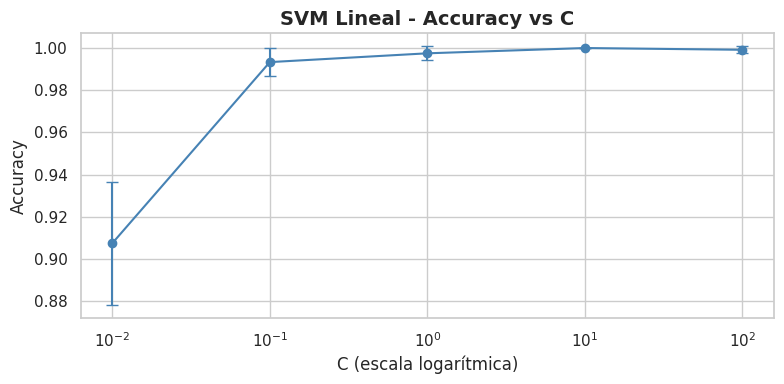

In [ ]:
acc_means = []
acc_stds = []

for C in C_values:
    modelo = SVC(kernel='linear', C=C, random_state=13)
    acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
    acc_means.append(acc.mean())
    acc_stds.append(acc.std())

plt.figure(figsize=(8, 4))
plt.errorbar(C_values, acc_means, yerr=acc_stds, marker='o', capsize=4, color='steelblue')
plt.xscale('log')
plt.xlabel('C (escala logarítmica)')
plt.ylabel('Accuracy')
plt.title('SVM Lineal - Accuracy vs C', fontsize=14, fontweight='bold')
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretación:**

- El accuracy mejora notablemente al aumentar C desde 0.01 hasta 10, donde alcanza su punto máximo con 1.0000 ± 0.0000.

- A partir de C=10 el rendimiento se estabiliza e incluso baja levemente en C=100.

- La barra de error en C=0.01 es la más grande, indicando mayor inestabilidad entre folds.

### **2.3 Selección del mejor modelo**

Se selecciona **C=10** como la mejor configuración, con un accuracy, precisión y recall de 1.0000 ± 0.0000 en los 5 folds. Si bien C=1 también muestra muy buen rendimiento (0.9975), C=10 logra clasificación perfecta con total estabilidad entre folds. Se descarta C=100 ya que, aunque tiene métricas muy altas, muestra una leve caída respecto a C=10, lo que podría indicar un leve sobreajuste.

---

## **3. SVM con kernel gaussiano (RBF)**

### **3.1 Selección de hiperparámetros**

In [ ]:
C_values    = [0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1]

resultados_svm_rbf = []

for C in C_values:
    for gamma in gamma_values:
        modelo = SVC(kernel='rbf', C=C, gamma=gamma, random_state=13)

        acc    = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
        prec   = cross_val_score(modelo, X, y, cv=cv, scoring='precision_weighted')
        recall = cross_val_score(modelo, X, y, cv=cv, scoring='recall_weighted')

        resultados_svm_rbf.append({
            'C': C,
            'gamma': gamma,
            'Accuracy':  f"{acc.mean():.4f} ± {acc.std():.4f}",
            'Precision': f"{prec.mean():.4f} ± {prec.std():.4f}",
            'Recall':    f"{recall.mean():.4f} ± {recall.std():.4f}"
        })

df_svm_rbf = pd.DataFrame(resultados_svm_rbf)
display(df_svm_rbf)

,C,gamma,Accuracy,Precision,Recall
0,0.1,0.001,0.8633 ± 0.0259,0.8882 ± 0.0202,0.8633 ± 0.0259
1,0.1,0.010,0.8708 ± 0.0250,0.8957 ± 0.0207,0.8708 ± 0.0250
2,0.1,0.100,0.9642 ± 0.0062,0.9693 ± 0.0069,0.9642 ± 0.0062
3,0.1,1.000,0.9850 ± 0.0062,0.9864 ± 0.0058,0.9850 ± 0.0062
4,1.0,0.001,0.8650 ± 0.0248,0.8895 ± 0.0194,0.8650 ± 0.0248
5,1.0,0.010,0.9517 ± 0.0104,0.9537 ± 0.0112,0.9517 ± 0.0104
6,1.0,0.100,0.9942 ± 0.0042,0.9944 ± 0.0040,0.9942 ± 0.0042
7,1.0,1.000,0.9975 ± 0.0033,0.9975 ± 0.0033,0.9975 ± 0.0033
8,10.0,0.001,0.9525 ± 0.0141,0.9542 ± 0.0138,0.9525 ± 0.0141
9,10.0,0.010,0.9967 ± 0.0031,0.9967 ± 0.0031,0.9967 ± 0.0031


---

### **3.2 Comparación de configuraciones**

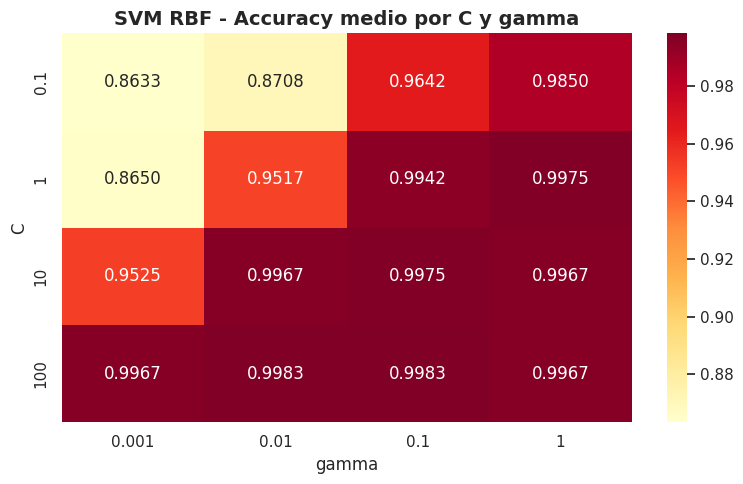

In [ ]:
# Extraer solo las medias de accuracy para el heatmap
acc_matrix = pd.DataFrame(index=C_values, columns=gamma_values, dtype=float)

for res in resultados_svm_rbf:
    c = res['C']
    g = res['gamma']
    acc_val = float(res['Accuracy'].split(' ')[0])
    acc_matrix.loc[c, g] = acc_val

plt.figure(figsize=(8, 5))
sns.heatmap(acc_matrix, annot=True, fmt='.4f', cmap='YlOrRd',
            xticklabels=gamma_values, yticklabels=C_values)
plt.title('SVM RBF - Accuracy medio por C y gamma', fontsize=14, fontweight='bold')
plt.xlabel('gamma')
plt.ylabel('C')
plt.tight_layout()
plt.show()

**Interpretación:**  

- Se observa claramente que el rendimiento del modelo depende fuertemente de la combinación de C y gamma.  

- Los valores bajos de gamma (0.001 y 0.01) con C bajo generan los peores resultados, mientras que a medida que aumentan ambos parámetros el accuracy mejora notablemente.

- La zona más oscura del heatmap (esquina inferior derecha) concentra las mejores combinaciones.

---

### **3.3 Selección del mejor modelo**

Se selecciona **C=100, gamma=0.01** como la mejor configuración, con accuracy 0.9983 ± 0.0020, precisión 0.9984 y recall 0.9983. Si bien C=100 con gamma=0.1 llega al mismo accuracy, se prefiere gamma=0.01 ya que un valor más bajo de gamma reduce el riesgo de sobreajuste.

---

## **4. Random Forest**

### **4.1 Selección de hiperparámetros**

In [ ]:
n_estimators_values = [50, 100, 200, 500]
max_depth_values = [5, 10, 20, None]

resultados_rf = []

for n_est in n_estimators_values:
    for max_dep in max_depth_values:
        modelo = RandomForestClassifier(n_estimators=n_est, max_depth=max_dep, random_state=13, n_jobs=-1)

        acc    = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy')
        prec   = cross_val_score(modelo, X, y, cv=cv, scoring='precision_weighted')
        recall = cross_val_score(modelo, X, y, cv=cv, scoring='recall_weighted')

        resultados_rf.append({
            'n_estimators': n_est,
            'max_depth': str(max_dep),
            'Accuracy':  f"{acc.mean():.4f} ± {acc.std():.4f}",
            'Precision': f"{prec.mean():.4f} ± {prec.std():.4f}",
            'Recall':    f"{recall.mean():.4f} ± {recall.std():.4f}"
        })

df_rf = pd.DataFrame(resultados_rf)
display(df_rf)

,n_estimators,max_depth,Accuracy,Precision,Recall
0,50,5,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
1,50,10,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
2,50,20,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
3,50,None,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
4,100,5,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
5,100,10,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
6,100,20,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
7,100,None,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
8,200,5,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017
9,200,10,0.9992 ± 0.0017,0.9992 ± 0.0016,0.9992 ± 0.0017


---

### **4.2 Comparación de configuraciones**

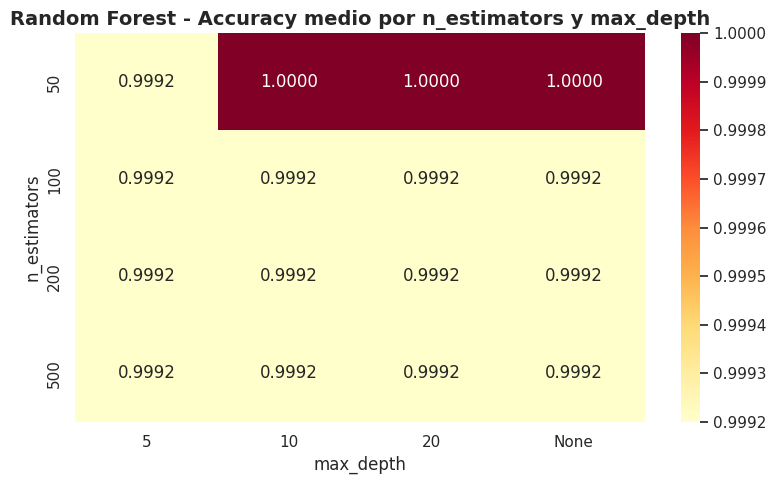

In [ ]:
acc_matrix_rf = pd.DataFrame(index=n_estimators_values, columns=[str(d) for d in max_depth_values], dtype=float)

for res in resultados_rf:
    n = res['n_estimators']
    d = res['max_depth']
    acc_val = float(res['Accuracy'].split(' ')[0])
    acc_matrix_rf.loc[n, d] = acc_val

plt.figure(figsize=(8, 5))
sns.heatmap(acc_matrix_rf, annot=True, fmt='.4f', cmap='YlOrRd',
            xticklabels=[str(d) for d in max_depth_values],
            yticklabels=n_estimators_values)
plt.title('Random Forest - Accuracy medio por n_estimators y max_depth', fontsize=14, fontweight='bold')
plt.xlabel('max_depth')
plt.ylabel('n_estimators')
plt.tight_layout()
plt.show()

**Interpretación:**  

- Se observa claramente que con n_estimators=50 y max_depth≥10 el modelo ya alcanza accuracy perfecto (1.0000 ± 0.0000).  

- Aumentar la cantidad de estimadores a 100, 200 o 500 no mejora el rendimiento, manteniéndose en 0.9992 para todas las profundidades.   

- Esto indica que el dataset es suficientemente separable y que árboles más numerosos no aportan información adicional.

### **4.3 Selección del mejor modelo**

Se selecciona **n_estimators=50, max_depth=10** como la mejor configuración, con accuracy, precisión y recall perfectos (1.0000 ± 0.0000). Se prefiere esta combinación por ser la más simple y rápida entre las que logran el máximo rendimiento.

---

### **4.4 Importancia de variables**

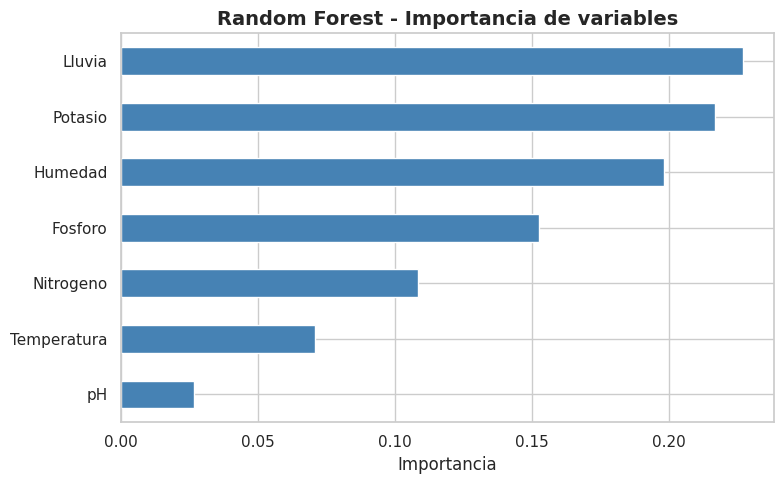

In [ ]:
mejor_rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=13, n_jobs=-1)
mejor_rf.fit(X, y)

importancias = pd.Series(mejor_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importancias.plot(kind='barh', color='steelblue')
plt.title('Random Forest - Importancia de variables', fontsize=14, fontweight='bold')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

**Interpretación:**

- `Lluvia, Potasio y Humedad` son las tres variables más importantes para el modelo, concentrando la mayor parte del poder predictivo.

- `Fósforo y Nitrógeno` tienen una importancia moderada.

- `Temperatura y pH` son las menos influyentes.

---

## **5. Comparación de modelos**

### **5.1 Tabla comparativa**

In [ ]:
comparacion = pd.DataFrame({
    'Modelo': ['SVM Lineal', 'SVM RBF', 'Random Forest'],
    'Mejor Configuración': [
        'C=10',
        'C=100, gamma=0.01',
        'n_estimators=50, max_depth=10'
    ],
    'Accuracy': [
        '1.0000 ± 0.0000',
        '0.9983 ± 0.0020',
        '1.0000 ± 0.0000'
    ],
    'Precision': [
        '1.0000 ± 0.0000',
        '0.9984 ± 0.0019',
        '1.0000 ± 0.0000'
    ],
    'Recall': [
        '1.0000 ± 0.0000',
        '0.9983 ± 0.0020',
        '1.0000 ± 0.0000'
    ]
})

comparacion

,Modelo,Mejor Configuración,Accuracy,Precision,Recall
0,SVM Lineal,C=10,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
1,SVM RBF,"C=100, gamma=0.01",0.9983 ± 0.0020,0.9984 ± 0.0019,0.9983 ± 0.0020
2,Random Forest,"n_estimators=50, max_depth=10",1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000


**Interpretación:**  

- Los resultados muestran que SVM Lineal y Random Forest alcanzan métricas perfectas en las tres medidas evaluadas (Accuracy, Precision y Recall), mientras que SVM con kernel RBF obtiene un rendimiento ligeramente inferior.

- En todos los casos los resultados son muy altos, lo que indica que las variables disponibles permiten separar adecuadamente las distintas clases de cultivos

---

### **5.2 Matriz de confusión**

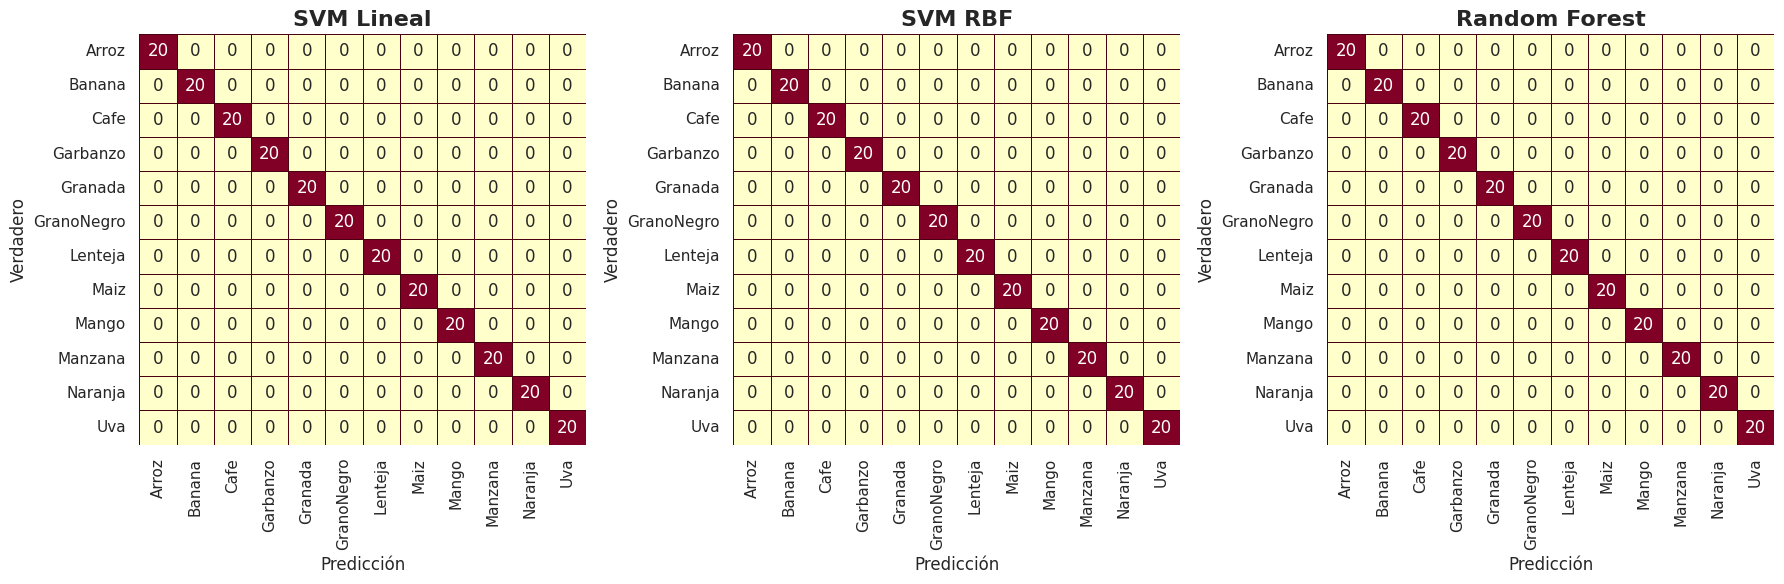

In [ ]:
X = df.drop('Cultivo', axis=1)
y = df['Cultivo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=13
)

modelos = {
    'SVM Lineal': SVC(kernel='linear', C=10, random_state=13),
    'SVM RBF': SVC(kernel='rbf', C=100, gamma=0.01, random_state=13),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=10, random_state=13)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (nombre, modelo) in zip(axes, modelos.items()):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd',
                xticklabels=le.classes_, yticklabels=le.classes_,
                linewidths=0.5, linecolor='#4a0010', ax=ax, cbar=False)

    ax.set_title(nombre, fontsize=16, fontweight='bold')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Verdadero')
    ax.tick_params(axis='x', rotation=90)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

**Interpretación:**  

- Las matrices de confusión muestran un desempeño perfecto para los tres algoritmos. Todas las observaciones fueron clasificadas correctamente.

- Este resultado coincide con las métricas obtenidas durante la validación cruzada y confirma que las variables del conjunto de datos permiten diferenciar con gran precisión los distintos tipos de cultivos.

- Dado que los tres modelos presentan el mismo comportamiento en esta prueba, la elección final se basará en la comparación de métricas, estabilidad entre folds, interpretabilidad y complejidad computacional de cada algoritmo.

---

### **5.3 Selección del modelo**

Si bien los tres modelos obtuvieron resultados muy altos, SVM Lineal y Random Forest fueron los que alcanzaron el mejor desempeño, con valores perfectos de Accuracy, Precision y Recall, además de una desviación estándar nula en la validación cruzada, lo que indica una excelente estabilidad entre folds.

Por otro lado, SVM RBF presentó métricas apenas inferiores y una mayor complejidad computacional debido a la necesidad de ajustar dos hiperparámetros (C y gamma).

Entre los dos modelos con mejor rendimiento, Random Forest ofrece una ventaja adicional en términos de interpretabilidad, ya que permite analizar la importancia de las variables utilizadas para realizar las predicciones. Además, logró estos resultados utilizando una configuración relativamente simple (50 árboles y profundidad máxima de 10).

Por estas razones, se considera que **Random Forest es el modelo más adecuado para este problema**, ya que combina un desempeño perfecto, alta estabilidad, buena interpretabilidad y un costo computacional razonable.

---

## **Conclusión**

Los resultados obtenidos muestran que las variables del dataset permiten identificar los distintos cultivos con un nivel de precisión muy alto. Los tres modelos evaluados tuvieron un desempeño excelente, con métricas muy cercanas o iguales al 100% y una gran estabilidad entre los distintos folds de validación.

Si bien SVM Lineal y Random Forest lograron resultados equivalentes en términos de rendimiento, Random Forest resultó la alternativa más conveniente, ya que además de alcanzar métricas perfectas permite interpretar mejor cuáles son las variables más importantes para la clasificación.

En general, este trabajo permitió aplicar distintas técnicas de minería de datos sobre un problema real y comparar sus resultados de manera objetiva. Los resultados obtenidos muestran que estos modelos pueden ser herramientas muy útiles para apoyar la toma de decisiones en el ámbito agrícola.

---